# COSYNE abstract figure — one dense summary of the project

One 180 mm figure, panels in the order of the story:

| | panel | drawn by |
|---|---|---|
| a | task diagram (space for the Inkscape drawing) | here |
| b | what the states are: paw states' vigor and left − right laterality, and the whisking and licking states' z-scored whisker motion energy and lick count | `fig_segmentation` `draw_D` + here (from the states files) |
| c | the three segmentations (paw, whisking, licking) over a 20 s snippet | `fig_segmentation` `draw_F` |
| d | how the states are used across the trial: occupancy per epoch, paw states and whisking / licking | `fig_segmentation` `draw_G` (its panel e) |
| e | mouse and lab identification from syllables, the raw signal and trial measures | `vigor/zscore/ci_segmentation_vs_raw.csv` + `ci_trial_measures.csv` (same protocol) |
| f | mice in the LD1–LD2 plane, with the LD1 colour bar shared by the figure | `fig_ld1` `draw_A` |
| g | syllable use along LD1 | `fig_ld1` `draw_B` |
| h | trial-level correlates of LD1 | `fig_ld1` panel C data |
| i | engagement: GLM-HMM weights, psychometric and chronometric curves per state; state switches and the engaged posterior (log ratio) vs LD1 | `fig_engagement` `draw_B`, `draw_C`, `corr_ax` |
| j | neural correlates, compressed: per metric, the time course by LD1 tercile beside its row of the effect map | `lda1_neural_metrics` |
| k | individuality across learning: where the timepoints sit in training (example mice), and the proficient LDA identifying the mouse at each | `learning_individuality/dataset_timepoints_overview.ipynb` panel A; numbers from `lda_sweep_timepoints.ipynb` |

**How the panels are drawn.** Each source notebook's code cells (everything before its assembly cell) are executed into their own namespace, and its `draw_*` functions are called here — so a panel is literally the same code as in its own figure, nothing copied. Their single-panel previews are suppressed. This makes the notebook slow the first time (fig_segmentation, fig_ld1 and fig_engagement each run; fig_ld1 caches its identification results).

**Consistency notes.**
* LD1 is the current LDA file everywhere, **including the neural panel h**: the cached neural tables carry an older LD1 (r = −0.88, opposite sign), which is replaced before the tests are rerun here — so h's numbers are not `fig_neural`'s rows a–c.
* Panel e: all six bars use one protocol (`vigor/lda/zscore_cost`: shrinkage LDA 0.5, ≤ 3 sessions per mouse; mouse ID leave-one-session-out, lab ID with the test mouse's sessions all held out; 95 % CI bootstrap over mice). Syllables / raw: `ci_segmentation_vs_raw.py` (260 sessions, 56 mice); trial measures: `ci_trial_measures.py` (10 session-level task measures, 234 sessions, 55 mice).
* Panel k's accuracies are **transcribed** from the stored output of `lda_sweep_timepoints.ipynb` (run on the other machine; its syllable files are not on this one). That analysis uses its own syllable set (`left_paw_wheel`, k = 8), not the 360-feature set of panels e–j. Rerun it and update `TIMEPOINTS_RESULT` if it changes.

**Inputs on this machine.** The source notebooks need data that lives on the analysis machine: `data/8_k_10_bin_syllables_02-10-2026`, `data/states_files/`, `data/session_trial_meta_19-08-2026`, `vigor/paw_bias/state_profiles_uniform.csv`. Where a source notebook cannot run here, its panels are filled with the **stored output image** of that panel's own preview cell in the source notebook (marked 'preview'), so the layout can be checked without the data; run the notebook on the analysis machine for the real, vector figure.

In [1]:
import sys, pathlib, re, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import Normalize
import matplotlib as mpl

FIGDIR = pathlib.Path.cwd().resolve()
while not (FIGDIR / 'fig_layout.py').exists() and FIGDIR != FIGDIR.parent:
    FIGDIR = FIGDIR / 'figure_generation' if (FIGDIR / 'figure_generation').exists() else FIGDIR.parent
PI = FIGDIR.parent
for p in [str(PI), str(PI / 'neural'), str(FIGDIR)]:
    if p not in sys.path:
        sys.path.insert(0, p)
# the LDA file was pickled under numpy 2; under numpy 1 its module paths need aliasing to unpickle
try:
    import numpy._core.numeric  # noqa: F401
except ModuleNotFoundError:
    import numpy.core.numeric, numpy.core.multiarray
    sys.modules['numpy._core.numeric'], sys.modules['numpy._core.multiarray'] = np.core.numeric, np.core.multiarray
import paper_style as ps
import fig_layout as fl
ps.use('paper')
FIG = 'cosyne_figure'
CACHE = FIGDIR / 'cache'

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


## Running the source notebooks

`load_panels` executes a notebook's code cells, in order, into a fresh namespace, stopping at its assembly cell (the one calling `fl.place_letters`). `plt.show` is replaced by a close for the duration, so the source notebooks' single-panel previews are not drawn here. `subs` patches a cell's source before it runs (here: fig_segmentation's snippet-picking embedding, which is not on this machine, and two example sessions instead of four).

In [2]:
import json

def load_panels(name, subs=None, stop_after=None, path=None, cwd=None):
    """The notebook's namespace, or None if its inputs are not on this machine (the panels it feeds are then
    drawn as labelled placeholders, so the layout can still be checked)."""
    try:
        return _load_panels(name, subs, stop_after, path, cwd)
    except (FileNotFoundError, OSError) as e:
        plt.show = _SHOW; plt.close('all'); ps.use('paper')
        print(f'{name}: NOT loaded -- missing input: {e}')
        return None

_SHOW = plt.show

def _load_panels(name, subs=None, stop_after=None, path=None, cwd=None):
    import os
    nb = json.load(open(path or FIGDIR / f'{name}.ipynb'))
    here = os.getcwd()
    if cwd:
        os.chdir(cwd)
    ns = {'__name__': f'cosyne_{name}'}
    show = _SHOW
    plt.show = lambda *a, **k: plt.close('all')
    try:
        for c in nb['cells']:
            if c['cell_type'] != 'code':
                continue
            src = ''.join(c['source'])
            if 'place_letters' in src or 'fig.savefig(path)' in src:
                break
            for a, b in (subs or {}).items():
                src = src.replace(a, b)
            exec(compile(src, f'{name}.ipynb', 'exec'), ns)
            if stop_after and stop_after in src:
                break
    finally:
        os.chdir(here)
        plt.show = show
        plt.close('all')
    ps.use('paper')
    print(f'{name}: loaded')
    return ns

import json
_emb = PI / 'clustering' / 'data_files' / 'mouse_LDA_5_bins_raw_shrink0.5_360_28-09-2026'
SEG_SUBS = {"N_EXAMPLES, MAX_MISSING = 4, 0.05": "N_EXAMPLES, MAX_MISSING = 2, 0.05"}
if not _emb.exists():   # the snippet-picking embedding of fig_segmentation is not on this machine: use the current one
    SEG_SUBS["clustering/data_files/mouse_LDA_5_bins_raw_shrink0.5_360_28-09-2026"] = \
        "clustering/data_files/mouse_LDA_5_bins_raw_shrink0.5_wmouse_360_02-10-2026"
SEG = load_panels('fig_segmentation', subs=SEG_SUBS)
LD = load_panels('fig_ld1')
# the LD1 x LD2 plane needs only the LDA file: if fig_ld1 cannot run in full here, run it up to draw_A
LDA_NS = LD if LD is not None else load_panels('fig_ld1', stop_after='def draw_A')
ENG = load_panels('fig_engagement')
# k: where the timepoints sit in training (its panel A), from the learning-individuality notebook
TL = load_panels('dataset_timepoints_overview', path=PI / 'learning_individuality' / 'dataset_timepoints_overview.ipynb',
                 cwd=PI / 'learning_individuality', stop_after='def trajectory_panel',
                 subs={'SHOW_LEARNING_CURVE = True': 'SHOW_LEARNING_CURVE = False', 'N_MICE = 12': 'N_MICE = 6'})
ps.use_paw_states('uniform')

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi
paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi
fig_segmentation: NOT loaded -- missing input: [Errno 2] No such file or directory: '/Users/ineslaranjeira/Documents/Repositories/representation_learning_variability/paper-individuality/data/8_k_10_bin_syllables_02-10-2026'


paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi
non-emerging metrics: nonemerging_session_metrics_01-10-2026.csv
260 sessions, 56 mice; between-mouse share LD1-3: [0.136 0.099 0.085]
paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi
fig_ld1: NOT loaded -- missing input: [Errno 2] No such file or directory: '/Users/ineslaranjeira/Documents/Repositories/representation_learning_variability/paper-individuality/data/8_k_10_bin_syllables_02-10-2026'
paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi
non-emerging metrics: nonemerging_session_metrics_01-10-2026.csv
260 sessions, 56 mice; between-mouse share LD1-3: [0.136 0.099 0.085]


paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi
fig_ld1: loaded
paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


244 sessions, 56 mice, 152677 trials, 13.2% disengaged; RT for 95.2% of trials
occupancy / switching counted over the first 400 trials of every session
54 mice
            stim       prev_choice        wsls        bias       abs_bias      
            mean   sem        mean   sem  mean   sem  mean   sem     mean   sem
role                                                                           
disengaged  1.03  0.11        1.22  0.16  0.28  0.08  0.21  0.16     0.89  0.10
engaged     8.23  0.38        0.43  0.04  0.22  0.03 -0.02  0.09     0.50  0.06
state   disengaged  engaged
cx                         
0.0000       0.290    0.270
0.0625       0.248    0.206
0.1250       0.248    0.179
0.2500       0.199    0.160
1.0000       0.145    0.138


K=4 switches over the first 400 trials
mouse_name      244
lab             244
LD1             244
bouts_dis_0     244
bouts_dis_1     244
bouts_dis_2     244
bouts_dis_3     244
bouts_dis_4     244
bouts_dis_5     244
bouts_dis_6     244
bouts_eng_0     244
bouts_eng_1     244
bouts_eng_2     244
bouts_eng_3     244
bouts_eng_4     244
bouts_eng_5     244
bouts_eng_6     244
short_bouts     244
long_bouts      244
frac_engaged    244
log_ratio       244
entropy         244
p_stay_eng      244
p_stay_dis      228
switches        244
n_ee            244
n_ed            244
n_de            244
n_dd            244
p_easy          244
gain_23         231
gain_24         231
bpt_K2          231
switches_k4     231
session level (pearson, fdr_bh) -- the one drawn:
               measure    n       r       p   p_fdr  significant
key                                                             
D1        frac_engaged  244  0.0371  0.5640  0.5640        False
D2           log_ratio  244  0.2386 


Controls, mouse level (n = 52 mice with every control defined): standardised LD1 coefficient (p), alone and with each control
control                     alone            + lab + easy-trial accuracy + absolute fit (K=2)       + switches
key measure                                                                                                   
D1  frac_engaged  +0.01 (p=0.969)  +0.20 (p=0.236)       -0.23 (p=0.066)      -0.13 (p=0.301)  +0.05 (p=0.732)
D2  log_ratio     +0.29 (p=0.036)  +0.53 (p=0.002)       +0.00 (p=0.992)      +0.10 (p=0.314)  +0.15 (p=0.316)
G   switches      -0.43 (p=0.001)  -0.62 (p=0.001)       -0.30 (p=0.024)      -0.39 (p=0.005)              NaN
I   switches_k4   -0.27 (p=0.049)  -0.51 (p=0.005)       -0.06 (p=0.601)      -0.15 (p=0.241)              NaN
S1  p_stay_eng    +0.42 (p=0.002)  +0.64 (p=0.000)       +0.22 (p=0.068)      +0.34 (p=0.011)  +0.01 (p=0.917)
S2  p_stay_dis    +0.21 (p=0.128)  +0.28 (p=0.084)       +0.36 (p=0.013)      +0.36 (p=0.006)  +

low  LD1 third, disengaged bouts / 400 trials: 1–2: 4.99, 3–5: 1.81, 6–10: 0.93, 11–20: 0.28, 21–50: 0.19, 51–100: 0.15, >100: 0.04
low  LD1 third, engaged    bouts / 400 trials: 1–2: 0.70, 3–5: 0.79, 6–10: 1.21, 11–20: 1.74, 21–50: 2.37, 51–100: 1.22, >100: 0.88
high LD1 third, disengaged bouts / 400 trials: 1–2: 2.32, 3–5: 1.23, 6–10: 0.76, 11–20: 0.56, 21–50: 0.43, 51–100: 0.07, >100: 0.01
high LD1 third, engaged    bouts / 400 trials: 1–2: 0.28, 3–5: 0.50, 6–10: 0.57, 11–20: 0.79, 21–50: 1.63, 51–100: 1.10, >100: 0.96
session LD1 vs short_bouts : r = -0.32, p = 2.89e-07 (n = 244)
session LD1 vs long_bouts  : r = -0.11, p = 0.0982 (n = 244)
session LD1 vs bouts_eng_0 : r = -0.21, p = 0.000748 (n = 244)
session LD1 vs bouts_eng_1 : r = -0.19, p = 0.00297 (n = 244)
session LD1 vs bouts_eng_2 : r = -0.24, p = 0.00018 (n = 244)
session LD1 vs bouts_eng_3 : r = -0.31, p = 1.19e-06 (n = 244)
session LD1 vs bouts_eng_4 : r = -0.25, p = 7.69e-05 (n = 244)
session LD1 vs bouts_eng_5 : r = -0

{'colors': ['#EDE8D8',
  '#BFB5C7',
  '#B688D8',
  '#A98605',
  '#84778F',
  '#9420CF',
  '#7C4702',
  '#3B2B1C'],
 'vigor_order': [0, 1, 2, 3, 4, 5, 6, 7],
 'lateral': {'left': [2, 5], 'right': [3, 6], 'symmetric': [0, 1, 4, 7]},
 'states_dir': 'data/paw_states_uniform_raw_sessionz',
 'profiles': 'vigor/paw_bias/state_profiles_uniform.csv',
 'syllable_paw_map': [0, 2, 1, 7, 6, 5, 3, 4]}

## Panel b — what the whisking and licking states are

Next to the paw states' vigor / laterality (`fig_segmentation` `draw_D`): for the whisking states (not whisking / whisking) the session-z-scored whisker motion energy, and for the licking states the session-z-scored lick count, in the bins assigned to each state. Per session (its states file: every bin, `whisker_me` and `Lick count` z-scored over the session, states decoded from `most_likely_states` as the syllables are), the mean per state; bars = mean ± SEM across sessions. Cached in `figure_generation/cache/` (the states files are only on the analysis machine).

In [3]:
WL_CACHE = CACHE / 'cosyne_whisk_lick_state_z.csv'

def whisk_lick_state_z():
    if WL_CACHE.exists():
        return pd.read_csv(WL_CACHE)
    if SEG is None:
        return None
    rows = []
    for s, m in SEG['seq'][['session', 'mouse_name']].drop_duplicates().itertuples(index=False):
        f = pathlib.Path(f"{SEG['STATES_FILES_DIR']}8_states_file_{s}_{m}")
        if not f.exists():
            continue
        d = pd.read_parquet(f, columns=['whisker_me', 'Lick count', 'most_likely_states'])
        _, wh, li = ps.decode_syllables(ps.paw_codes(d['most_likely_states'].to_numpy(float)), SEG['N_STATES'])
        z = lambda v: (v - np.nanmean(v)) / np.nanstd(v)
        me, lk = z(d['whisker_me'].to_numpy(float)), z(d['Lick count'].to_numpy(float))
        for state in (0, 1):
            rows.append(dict(session=s, channel='whisk', state=state, z=np.nanmean(me[wh == state])))
            rows.append(dict(session=s, channel='lick', state=state, z=np.nanmean(lk[li == state])))
    out = pd.DataFrame(rows)
    out.to_csv(WL_CACHE, index=False)
    return out

WLZ = whisk_lick_state_z()
if WLZ is not None:
    print(WLZ.groupby(['channel', 'state'])['z'].agg(['mean', 'sem', 'count']).round(3))

def draw_b(fig, spec):
    # paw states (fig_segmentation draw_D: vigor, left - right) beside the whisking and licking states
    g = spec.subgridspec(1, 2, width_ratios=[2.2, 1], wspace=0.35)
    axes = SEG['draw_D'](fig, g[0]) if SEG else mock_panel(fig, g[0], 'fig_segmentation', 'def draw_D', 'paw states')
    gw = g[1].subgridspec(2, 1, hspace=0.9)
    for k, (ch, title, xlab) in enumerate([('whisk', 'Whisking', 'z whisker ME'), ('lick', 'Licking', 'z lick count')]):
        ax = fig.add_subplot(gw[k]); axes.append(ax)
        if WLZ is None:
            placeholder(ax, f'{title.lower()}\n(states files\nnot here)')
            continue
        st = WLZ[WLZ['channel'] == ch].groupby('state')['z'].agg(['mean', 'sem'])
        cols = (SEG['WHISK_COLORS'] if ch == 'whisk' else SEG['LICK_COLORS']) if SEG else ['white', '0.5']
        ax.barh([0, 1], st['mean'], xerr=st['sem'], height=0.7, color=cols, edgecolor='#333333', lw=0.4,
                error_kw=dict(lw=0.6, ecolor='0.3'))
        ax.axvline(0, color='#333333', lw=0.6)
        ax.set_yticks([0, 1]); ax.set_yticklabels(['no', 'yes'], fontsize=plt.rcParams['ytick.labelsize'] * 0.85)
        ax.set_ylim(1.6, -0.6)
        ax.set_title(title, fontsize=plt.rcParams['font.size'] * 0.9, pad=2)
        ax.set_xlabel(xlab, fontsize=plt.rcParams['font.size'] * 0.8, labelpad=1)
        ax.tick_params(axis='x', labelsize=plt.rcParams['xtick.labelsize'] * 0.8)
    return axes

## Panel e — identification accuracy (new)

Mouse ID: syllables (360 features) and the dimension-matched raw signal (speed per paw + whisker motion energy + lick count, 160 features) from `ci_segmentation_vs_raw.csv` (`all` block; 95 % CI, bootstrap over mice); trial measures from `fig_ld1` panel E (10 session-level task measures; mean ± SD over training draws). Lab ID: syllables, with every session of the test mouse held out (lab signal that generalises to a new animal), chance 1/10. Dotted ticks: chance for each bar.

In [4]:
SR = pd.read_csv(PI / 'vigor' / 'zscore' / 'ci_segmentation_vs_raw.csv')
SR = SR[SR['channel'] == 'all']
TM = pd.read_csv(PI / 'vigor' / 'zscore' / 'ci_trial_measures.csv')     # same protocol (ci_trial_measures.py)
ID = pd.concat([SR, TM], ignore_index=True)
ID['source'] = ID['rep'].map(lambda r: 'Syllables' if r == 'syllables' else 'Trial measures' if r == 'trial measures'
                             else 'Raw signal' if str(r).startswith('raw') else None)
ID = ID.dropna(subset=['source']).set_index(['metric', 'source'])
E_SOURCES = [('Syllables', '0.15'), ('Raw signal', '0.6'), ('Trial measures', 'white')]
E_GROUPS = [('mouse', 'Mouse', 1 / 56), ('lab_lomo', 'Lab', 1 / 10)]
print(ID[['estimate', 'lo', 'hi']].round(3))

def draw_e(fig, spec):
    ax = fig.add_subplot(spec)
    w = 0.27
    for gi, (metric, glabel, chance) in enumerate(E_GROUPS):
        for si, (src, col) in enumerate(E_SOURCES):
            r = ID.loc[(metric, src)]
            x = gi + (si - 1) * w
            ax.bar(x, r['estimate'], width=w * 0.92, color=col, edgecolor='0.15', lw=0.6, label=src if gi == 0 else None)
            ax.errorbar(x, r['estimate'], yerr=[[r['estimate'] - r['lo']], [r['hi'] - r['estimate']]], fmt='none',
                        ecolor='0.15', lw=0.7)
        ax.plot([gi - 1.6 * w, gi + 1.6 * w], [chance, chance], color='0.3', ls=':', lw=0.8)
    ax.set_xticks(range(len(E_GROUPS))); ax.set_xticklabels([g[1] for g in E_GROUPS])
    ax.set_ylim(0, 1); ax.set_yticks([0, 0.5, 1]); ax.set_ylabel('Held-out ID accuracy')
    ax.legend(frameon=False, fontsize=plt.rcParams['legend.fontsize'] * 0.65, loc='lower center', bbox_to_anchor=(0.5, 1.0),
              ncol=3, handlelength=0.8, columnspacing=0.6, borderaxespad=0.1)
    return [ax]

                          estimate     lo     hi
metric    source                                
mouse     Syllables          0.850  0.799  0.898
          Raw signal         0.894  0.848  0.935
mouse_lab Syllables          0.751  0.685  0.813
          Raw signal         0.822  0.769  0.873
lab_lomo  Syllables          0.358  0.264  0.464
          Raw signal         0.577  0.458  0.687
lab_eta2  Syllables          0.174  0.131  0.217
          Raw signal         0.266  0.189  0.342
mouse     Trial measures     0.293  0.220  0.367
lab_lomo  Trial measures     0.120  0.064  0.187


## Panel h — trial-level correlates of LD1

The six measures of `fig_ld1` panel C (same data, Pearson r and FDR over the six; training time per mouse). One point per session, coloured by LD1; a line only where FDR-significant.

In [5]:
def placeholder(ax, text):
    for s_ in ax.spines.values():
        s_.set_visible(False)
    ax.set_xticks([]); ax.set_yticks([])
    ax.add_patch(Rectangle((0, 0), 1, 1, transform=ax.transAxes, fill=False, ec='0.75', ls='--', lw=0.6))
    ax.text(0.5, 0.5, text, transform=ax.transAxes, ha='center', va='center', fontsize=plt.rcParams['font.size'] * 0.7, color='0.55')
    return [ax]

def placeholder_panel(fig, spec, text):
    return placeholder(fig.add_subplot(spec), text)

import base64, io
def stored_preview(nb_name, marker, crop=None):
    # the stored output image of the cell whose source contains `marker` (a panel's own preview in its notebook);
    # crop = (x0, x1, y0, y1) as fractions of the image, to keep part of it
    nb = json.load(open(FIGDIR / f'{nb_name}.ipynb'))
    for c in nb['cells']:
        if marker in ''.join(c['source']):
            for o in c.get('outputs', []):
                if 'image/png' in o.get('data', {}):
                    img = plt.imread(io.BytesIO(base64.b64decode(o['data']['image/png'])), format='png')
                    ink = (img[..., :3].min(axis=2) < 0.97)      # trim the white margins round the stored panel
                    rows, cols = np.where(ink.any(1))[0], np.where(ink.any(0))[0]
                    if len(rows) and len(cols):
                        img = img[rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1]
                    if crop:
                        h_, w_ = img.shape[:2]
                        img = img[int(crop[2] * h_):int(crop[3] * h_), int(crop[0] * w_):int(crop[1] * w_)]
                    return img
    return None

def mock_panel(fig, spec, nb_name, marker, text, crop=None):
    # a source notebook that cannot run here: show its stored preview of the panel, for the layout only
    ax = fig.add_subplot(spec)
    img = stored_preview(nb_name, marker, crop)
    if img is None:
        return placeholder(ax, text)
    ax.imshow(img, interpolation='antialiased'); ax.set_axis_off()
    ax.text(1.0, 0.0, 'preview', transform=ax.transAxes, ha='right', va='bottom', fontsize=plt.rcParams['font.size'] * 0.55,
            color='0.6')
    return [ax]

G_PANELS = [(v, t) for v, t, _ in LD['C_VARS']] if LD is not None else []
LD1_ALL = (LD['beh'] if LD is not None else ENG['DATA'])['LD1'].to_numpy(float)
NORM = ps.ld1_norm(LD1_ALL)

def g_panel(ax, v, title):
    if v == 'switches':
        d = ENG['DATA'][['LD1', 'switches']].dropna()
        st = ENG['STATS'].loc['G']
        r, q, sig = st['r'], st['p_fdr'], st['significant']
    else:
        d = LD['c_data'](v)
        st = LD['C_STATS'].set_index('variable').loc[v]
        r, q, sig = st['r'], st['q'], st['significant']
    x, y = d['LD1'].to_numpy(float), d[v].to_numpy(float)
    ax.scatter(x, y, s=3 if v != 'log_training' else 6, lw=0, alpha=0.8, color=ps.LD1_CMAP(NORM(x)))
    ps.regline(ax, x, y, bool(sig))
    ax.set_box_aspect(1)
    ax.set_title(LD['C_PANEL_TITLE'].get(v, title) if (v != 'switches' and LD is not None) else title, fontsize=plt.rcParams['font.size'] * 0.75, pad=2)
    ax.text(0.03, 0.97, f'r = {r:+.2f}\nq = {q:.2g}', transform=ax.transAxes, ha='left', va='top',
            fontsize=plt.rcParams['font.size'] * 0.65, color='0.25')
    ax.tick_params(labelsize=plt.rcParams['xtick.labelsize'] * 0.8)
    ax.set_xlabel('')

def draw_g(fig, spec):
    g = spec.subgridspec(2, 3, wspace=0.65, hspace=0.6)
    axes = []
    if LD is None:      # fig_ld1 cannot run here: its stored panel-C preview
        axes += mock_panel(fig, g[:, :], 'fig_ld1', 'def draw_C', 'fig_ld1 C (data not here)')
    for k, (v, t) in enumerate(G_PANELS):
        ax = fig.add_subplot(g[k // 3, k % 3]); axes.append(ax)
        g_panel(ax, v, t)
        if k // 3 == 1:
            ax.set_xlabel('LD1' if v != 'log_training' else 'LD1 (mouse)', labelpad=1)
    return axes

## Panel i — engagement

`fig_engagement`'s own panels: the 2-state GLM-HMM's weights (engaged vs disengaged), the psychometric and chronometric curves per state, and state switches per session and the engaged posterior (log of mean P(engaged) / mean P(disengaged), the soft occupancy) against LD1 (`fig_engagement`'s statistics: Pearson, FDR within its family).

In [6]:
def draw_engagement(fig, spec):
    g = spec.subgridspec(1, 4, width_ratios=[1.25, 1.95, 0.9, 0.9], wspace=0.55)
    axes = ENG['draw_B'](fig, g[0])
    axes += ENG['draw_C'](fig, g[1], legend=False)
    axes += [ENG['corr_ax'](fig.add_subplot(g[2]), 'D2'), ENG['corr_ax'](fig.add_subplot(g[3]), 'G')]
    # fig_engagement draws these for a wider cell: shorter labels so they fit here
    SHORT = {'stim': 'Stim.', 'prev_choice': 'Prev.', 'wsls': 'WSLS', 'bias': 'Bias'}
    for ax, coefs in zip(axes[:2], [['stim'], ENG['COEFS'][1:]]):
        ax.set_xticks(range(len(coefs))); ax.set_xticklabels([SHORT[k].replace('\n', ' ') for k in coefs], rotation=40, ha='right',
                                                            rotation_mode='anchor')
    axes[0].set_ylabel('GLM weight'); axes[0].set_yticks([0, 4, 8])
    axes[1].legend(frameon=False, loc='lower left', bbox_to_anchor=(-0.6, 1.0), ncol=2, handlelength=1.6, borderaxespad=0.1,
                   columnspacing=0.8)
    ax_p, ax_c = axes[2], axes[3]
    ax_p.set_xlabel('Contrast (%)'); ax_c.set_xlabel('|Contrast| (%)'); ax_c.set_ylabel('RT (s)'); ax_p.set_ylabel('P(right)')
    ax_c.set_xticks([0, 25, 100]); ax_c.set_xticklabels(['0', '25', '100'])
    p = ax_c.get_position(); ax_c.set_position([p.x0 + 0.012, p.y0, p.width - 0.012, p.height])
    axes[4].set_title('Engaged posterior'); axes[4].set_ylabel('log P(eng.) / P(dis.)')
    axes[5].set_title('State switches'); axes[5].set_ylabel('Switches / 400 tr.')
    for ax in axes[4:]:
        ax.set_xlabel('LD1', labelpad=1)
        ax.set_box_aspect(None)
    for t in axes[4].texts:      # the posterior's points fill the lower right: its stats go top left
        t.set_position((0.04, 0.97)); t.set_ha('left'); t.set_va('top')     # fig_engagement squares these; here they take the row's full height like the others
    return axes

## Panel j — neural correlates, compressed

One row per metric (firing rate, Fano factor, $r_{SC}$):
* **left: the time course** per LD1 tercile (equal-count bins, mean ± SEM across sessions; the baseline window grey, the post-stimulus window hatched — the windows the tests read);
* **right: that metric's four tests** as a row of an effect map — baseline, post-stimulus, response magnitude (quench), onset; colour and size = partial r with LD1 (the grid's own statistic: region and trial-count covariates, sessions permuted), filled = FDR q < 0.05 within the metric, empty = n.s.; the r value is printed under each dot.

LD1 is the current file (`LD1_SOURCE = 'current'` via `run_behavior_axes.config()`); the tests are cached in `figure_generation/cache/`.

In [7]:
import lda1_neural_metrics as nm
import run_behavior_axes as rba
import behaviour_models as bm
ncfg = rba.config()
NT = nm.apply_cohort(nm.load_tables(cfg=ncfg, verbose=False), ncfg, 'common', verbose=False)
# rba.config() sets LD1_SOURCE = 'current': apply_cohort swaps in the current LDA file's LD1
_ncache = CACHE / 'cosyne_neural_tests_currentLD1.pkl'
if _ncache.exists():
    NRES = pd.read_pickle(_ncache)
else:
    NRES = nm.run_tests(NT, ncfg, predictor='lda_1', verbose=False)
    NRES.to_pickle(_ncache)
print(NRES[['metric', 'test', 'r_partial', 'p_perm', 'q_fdr_metric']].round(4).to_string(index=False))
N_TERC = 3
H_ROWS = [('Firing rate', 'fr', 'FR (Hz)'), ('Fano factor', 'ff', 'FF'), ('Noise correlation', 'rsc', '$r_{SC}$')]
H_COLS = ['Base', 'Post', 'Quench', 'Onset']
H_NORM = Normalize(-0.2, 0.2)
TSEC = nm.load_tables(cfg=ncfg, verbose=False)['time']['tsec'].to_numpy()

def draw_h(fig, spec):
    # one row per metric: its time course by LD1 tercile (equal-count bins, mean +/- SEM across sessions; baseline
    # window grey, post-stimulus hatched), and to its right that metric's tests as a row of the effect map --
    # colour = partial r with LD1, filled = FDR q < 0.05 within the metric, empty = n.s.
    g = spec.subgridspec(len(H_ROWS) + 1, 2, width_ratios=[0.6, 1], height_ratios=[1] * len(H_ROWS) + [0.18],
                         hspace=0.28, wspace=0.12)
    R = NRES.set_index(['metric', 'test'])
    cols = ps.LD1_CMAP(np.linspace(0.05, 0.95, N_TERC))
    keep = (TSEC >= -0.3) & (TSEC <= 0.6)
    axes = []
    for i, (metric, key, ylab) in enumerate(H_ROWS):
        ax = fig.add_subplot(g[i, 0]); axes.append(ax)
        pre, post = ncfg[nm.PSTH_ROWS[metric][3]], ncfg[nm.PSTH_ROWS[metric][4]]
        ax.axvspan(*pre, facecolor=ps.NEUTRAL, alpha=0.2, lw=0, zorder=0)
        ax.axvspan(*post, facecolor='none', edgecolor=ps.NEUTRAL, hatch='////', lw=0, alpha=0.5, zorder=0)
        agg = nm.bin_curves(NT['curves'], key, n_bins=N_TERC, binning='quantile', predictor='lda_1')
        for b in sorted(agg):
            M = agg[b]; m = np.nanmean(M, 0); se = np.nanstd(M, 0) / np.sqrt(M.shape[0])
            ax.plot(TSEC[keep], m[keep], color=cols[b], lw=0.9, label=['low', 'mid', 'high'][b] + ' LD1')
            ax.fill_between(TSEC[keep], (m - se)[keep], (m + se)[keep], color=cols[b], alpha=0.25, lw=0)
        ax.axvline(0, color='k', ls='--', lw=0.5, alpha=0.5)
        ax.set_xlim(-0.3, 0.6); ax.set_xticks([-0.2, 0, 0.2, 0.4]); ax.set_ylabel(ylab, labelpad=1)
        ax.tick_params(labelsize=plt.rcParams['xtick.labelsize'] * 0.8)
        if i < len(H_ROWS) - 1:
            ax.tick_params(labelbottom=False)
        else:
            ax.set_xlabel('Time from stim. (s)', labelpad=1)
        if i == 0:
            ax.legend(frameon=False, fontsize=plt.rcParams['legend.fontsize'] * 0.6, loc='lower left', ncol=3,
                      bbox_to_anchor=(0, 1.0), handlelength=0.8, columnspacing=0.6, borderaxespad=0.1)
        # this metric's row of the effect map
        mx = fig.add_subplot(g[i, 1]); axes.append(mx)
        for j, t in enumerate(nm.TEST_COLS):
            if (metric, t) not in R.index:
                mx.text(j, 0, '–', ha='center', va='center', color='0.6')
                continue
            r_ = R.loc[(metric, t)]
            col = ps.CORR_CMAP(H_NORM(r_['r_partial']))
            sig = r_['q_fdr_metric'] < 0.05
            mx.scatter(j, 0, s=15 + 300 * abs(r_['r_partial']), color=col if sig else 'white',
                       edgecolors='0.2' if sig else col, linewidths=0.8, zorder=3)
            mx.text(j, -0.7, f"{r_['r_partial']:+.2f}", ha='center', va='center',
                    fontsize=plt.rcParams['font.size'] * 0.55, color='0.3')
        mx.set_xlim(-0.6, len(nm.TEST_COLS) - 0.4); mx.set_ylim(-1.0, 0.6)
        mx.set_yticks([]); mx.set_xticks(range(len(H_COLS)))
        mx.set_xticklabels(H_COLS if i == 0 else [], fontsize=plt.rcParams['xtick.labelsize'] * 0.75)
        mx.xaxis.set_ticks_position('top'); mx.tick_params(length=0)
        for s_ in mx.spines.values():
            s_.set_visible(False)
    cax = fig.add_subplot(g[len(H_ROWS), 1])
    cb = fig.colorbar(mpl.cm.ScalarMappable(norm=H_NORM, cmap=ps.CORR_CMAP), cax=cax, orientation='horizontal')
    cb.set_label('partial r with LD1 (filled: q < 0.05)', fontsize=plt.rcParams['font.size'] * 0.65, labelpad=1)
    cb.set_ticks([-0.2, -0.1, 0, 0.1, 0.2]); cb.outline.set_visible(False); cb.ax.tick_params(labelsize=plt.rcParams['xtick.labelsize'] * 0.65, length=2)
    return axes

           metric               test  r_partial  p_perm  q_fdr_metric
      Firing rate           Baseline     0.0404  0.0460        0.0920
      Firing rate      Post-stimulus     0.0218  0.2240        0.2340
      Firing rate Response magnitude     0.0146  0.2340        0.2340
      Firing rate     Response onset     0.0793  0.0020        0.0080
      Fano factor           Baseline    -0.0222  0.3225        0.3225
      Fano factor      Post-stimulus    -0.0782  0.0035        0.0047
      Fano factor Response magnitude     0.0749  0.0000        0.0000
      Fano factor     Response onset    -0.0458  0.0005        0.0010
Noise correlation           Baseline    -0.1681  0.0180        0.0270
Noise correlation      Post-stimulus    -0.2176  0.0005        0.0015
Noise correlation Response magnitude     0.1123  0.0500        0.0500


## Panel k — individuality across learning

Left: where the datasets sit in training — every task session of six example mice chosen to span the range of training length, shown in random order (grey ticks), the sessions that enter the analyses coloured by timepoint (`dataset_timepoints_overview.ipynb` panel A). Right: a shrinkage LDA fit on **proficient** sessions identifies the mouse from a session at an earlier timepoint (`lda_sweep_timepoints.ipynb`, per-timepoint mice). Bars: accuracy (95 % CI over mice); dashed tick: shuffled-label null; diamond: the same LDA on held-out proficient sessions of those mice (the ceiling). Stars: permutation p vs the null.

In [8]:
# transcribed from the stored output of learning_individuality/lda_sweep_timepoints.ipynb (PASS 2)
TIMEPOINTS_RESULT = pd.DataFrame([
    dict(tp='Early', label='Early', acc=0.0289, lo=0.0008, hi=0.0749, null=0.0270, p=0.2438, prof=0.9228, n_mice=37),
    dict(tp='Late', label='Late', acc=0.0924, lo=0.0353, hi=0.1676, null=0.0205, p=0.004975, prof=0.8912, n_mice=49),
    dict(tp='Pre-rec', label='Pre-rec', acc=0.5333, lo=0.4203, hi=0.6502, null=0.0286, p=0.004975, prof=0.8654, n_mice=37),
]).set_index('tp')

def draw_i(fig, spec):
    ax = fig.add_subplot(spec)
    for k, (tp, r) in enumerate(TIMEPOINTS_RESULT.iterrows()):
        col = ps.TIMEPOINT.get(tp, '0.5')
        ax.bar(k, r['acc'], width=0.68, color=col)
        ax.errorbar(k, r['acc'], yerr=[[r['acc'] - r['lo']], [r['hi'] - r['acc']]], fmt='none', ecolor='0.15', lw=0.7)
        ax.plot([k - 0.34, k + 0.34], [r['null']] * 2, color='0.2', ls='--', lw=0.7)
        ax.plot(k, r['prof'], 'D', ms=3.5, color=ps.TIMEPOINT.get('Proficient', 'k'), mec='white', mew=0.4)
        ax.text(k, r['hi'] + 0.03, ps.stars(r['p']), ha='center', va='bottom', fontsize=plt.rcParams['font.size'] * 0.8)
    ax.set_xticks(range(len(TIMEPOINTS_RESULT))); ax.set_xticklabels(TIMEPOINTS_RESULT['label'], fontsize=plt.rcParams['xtick.labelsize'] * 0.85)
    ax.set_ylim(0, 1.2); ax.set_yticks([0, 0.5, 1]); ax.set_ylabel('Mouse ID accuracy\n(proficient LDA)')   # headroom: legend above the diamonds
    from matplotlib.lines import Line2D
    ax.legend(handles=[Line2D([], [], marker='D', ls='none', ms=3.5, color=ps.TIMEPOINT.get('Proficient', 'k'), label='proficient (held out)'),
                       Line2D([], [], ls='--', color='0.2', lw=0.7, label='shuffled')],
              frameon=False, fontsize=plt.rcParams['legend.fontsize'] * 0.65, loc='upper left', handlelength=1.2, borderaxespad=0)
    return [ax]

def draw_k(fig, spec):
    g = spec.subgridspec(1, 2, width_ratios=[0.95, 1], wspace=0.45)
    axes = []
    if TL is not None:
        ax = fig.add_subplot(g[0]); axes.append(ax)
        mice = list(TL['EXAMPLES'])
        np.random.default_rng(3).shuffle(mice)      # spanning training length, but not shown in that order
        TL['trajectory_panel'](ax, mice)
        ax.set_yticklabels([f'Mouse {k + 1}' for k in range(len(mice))])
        ax.tick_params(axis='y', length=0)
        # stage names as on the bars beside it, short enough for the empty lower right of the timeline
        short = {'Early learning': 'Early', 'Late learning': 'Late', 'Pre-recording': 'Pre-rec', 'Proficient': 'Proficient'}
        h, l = ax.get_legend_handles_labels()
        ax.legend(h, [short.get(x, x) for x in l], frameon=False, ncol=1, loc='lower right', handletextpad=0.1,
                  borderaxespad=0.1, labelspacing=0.3)
    else:
        axes += mock_panel(fig, g[0], 'dataset_timepoints_overview', 'def trajectory_panel', 'timepoints in training')
    axes += draw_i(fig, g[1])
    return axes

## The assembled figure

180 mm wide, four rows, white space kept to a minimum, one type scale for every panel (`normalise_fonts`: ticks 5.5 pt, labels and titles 6.5 pt, legends 5.5 pt, in-panel notes 5 pt — the source notebooks sized their panels for larger cells). Row 1: a | b | c. Row 2: d | e | f (+ the LD1 colour bar) | g. Row 3: h | i. Row 4: j | k.

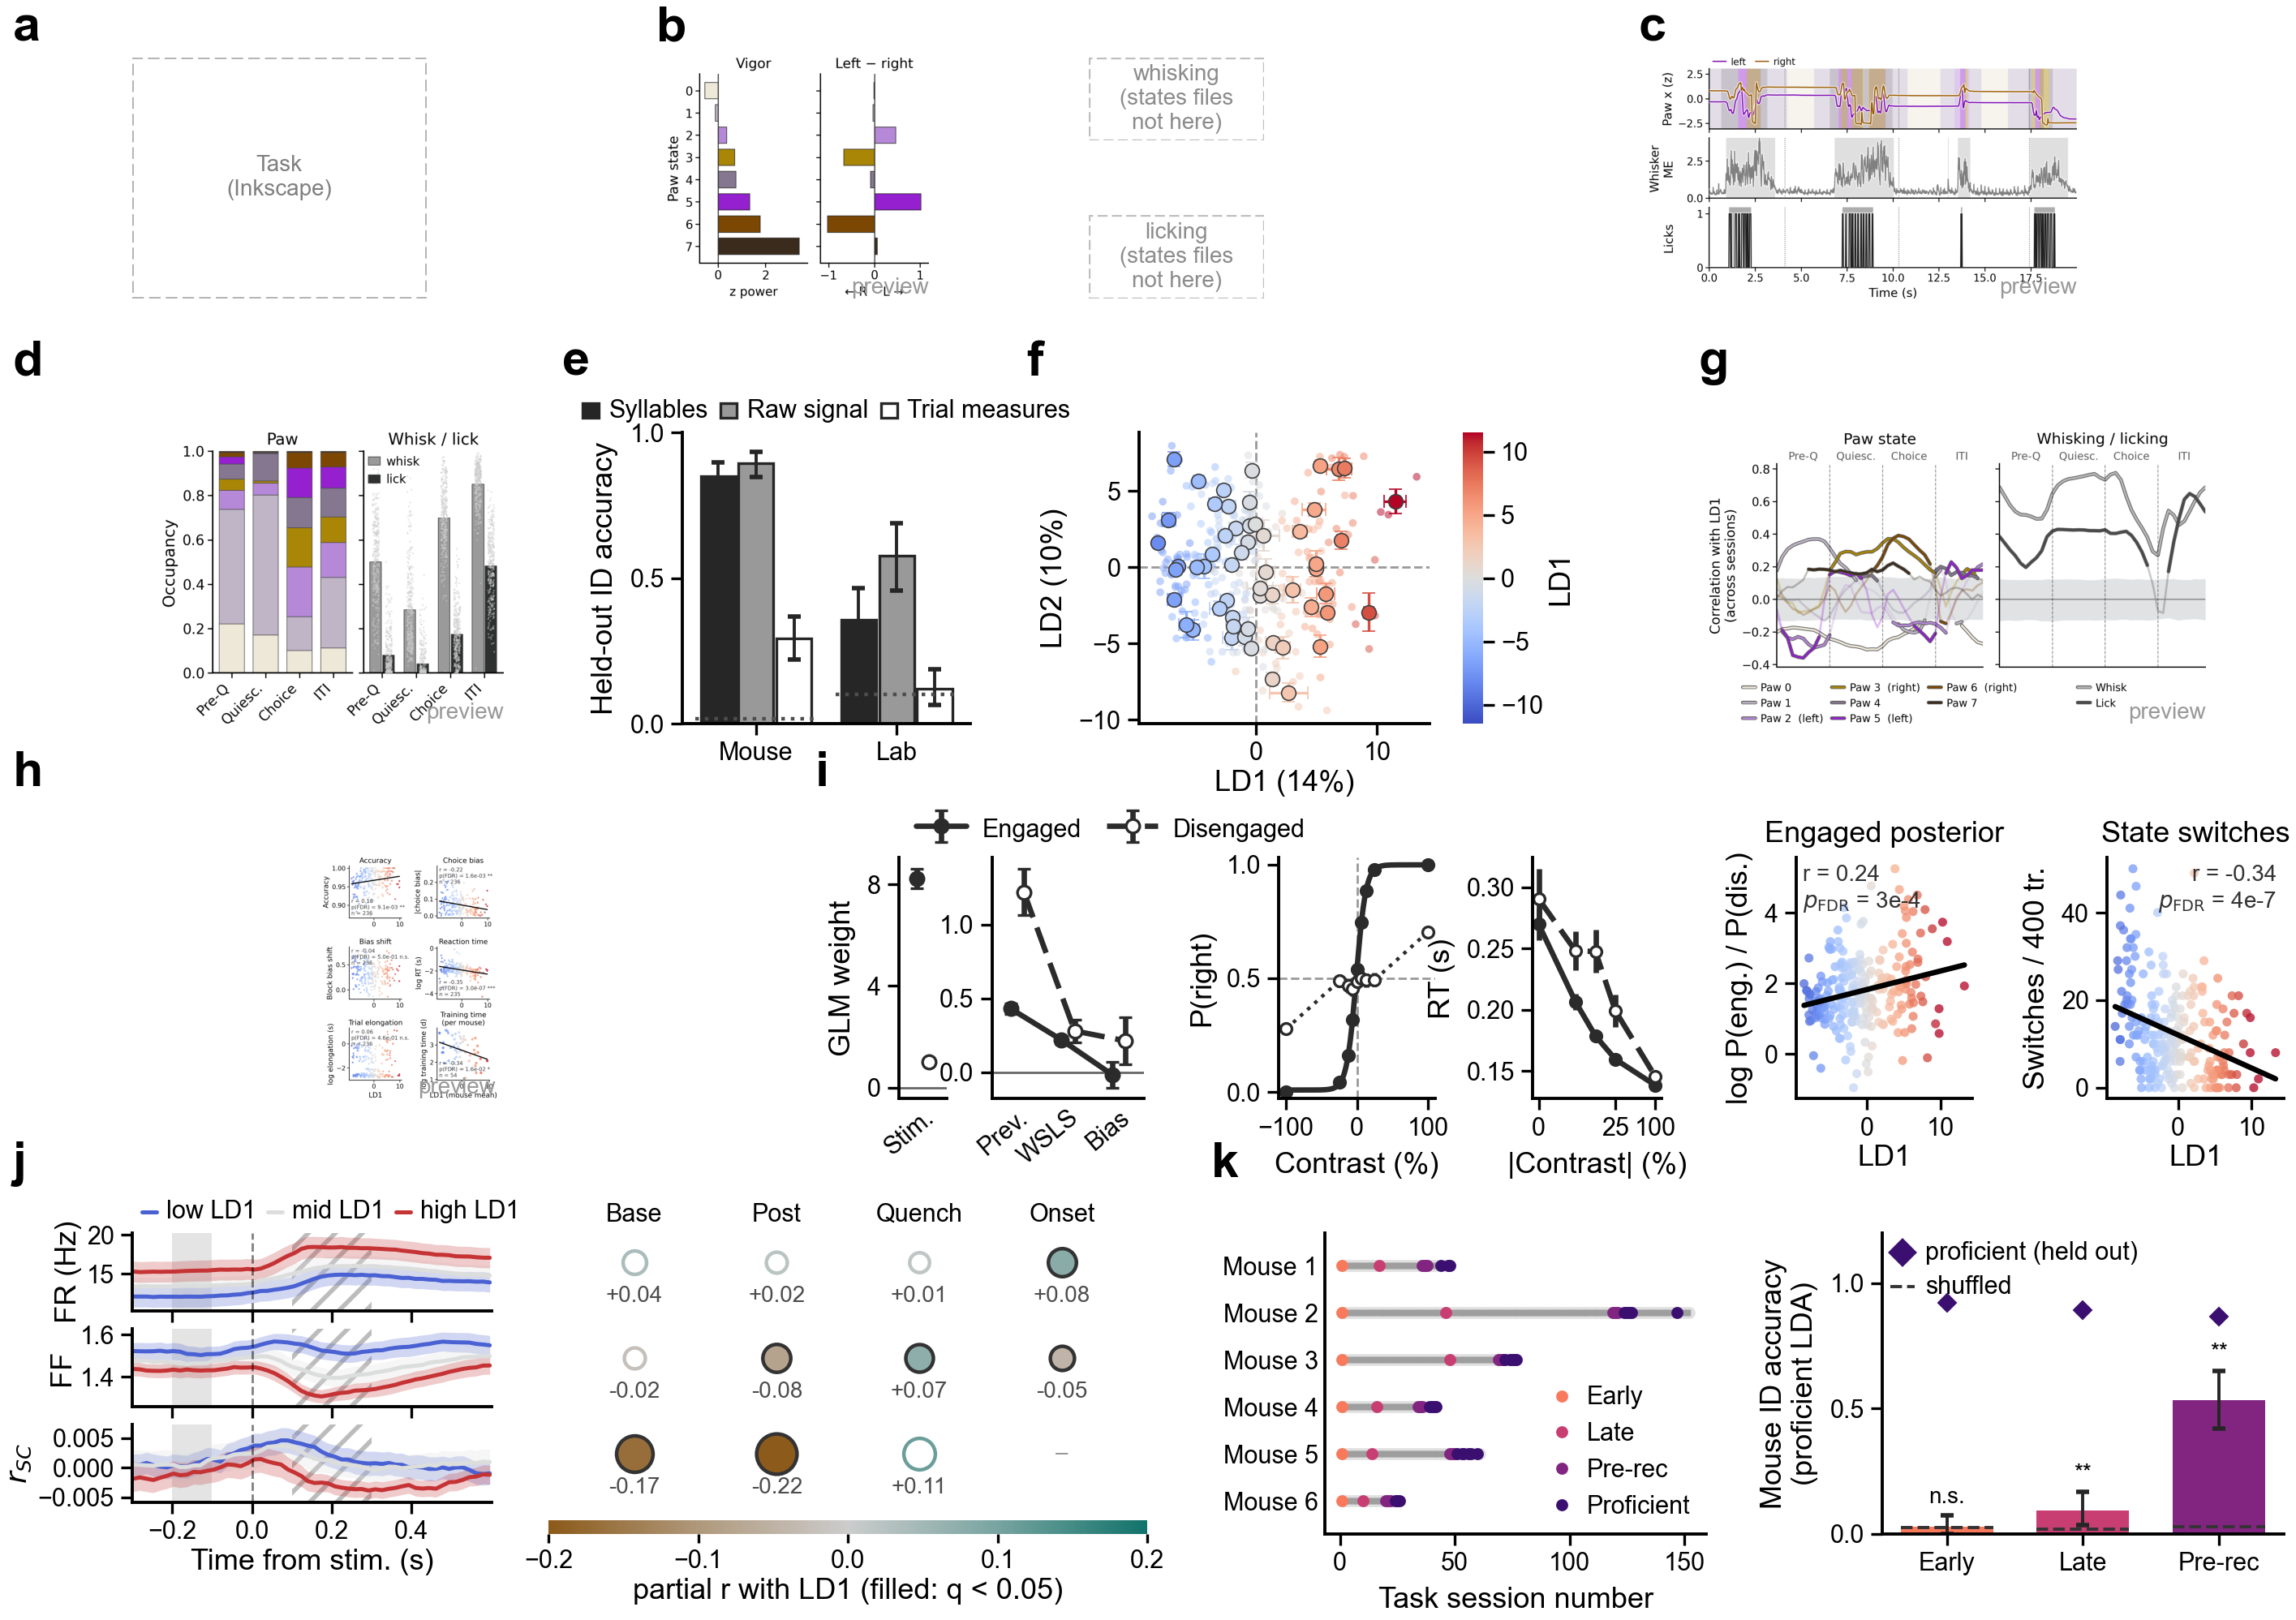

wrote figure_generation/figures/cosyne_figure_11-10-2026.svg


wrote figure_generation/figures/cosyne_figure.pdf


In [9]:
from datetime import date
FIG_H = 5.0
fig = plt.figure(figsize=(fl.FIG_WIDTH, FIG_H))
outer = fig.add_gridspec(4, 1, height_ratios=[1.2, 1.45, 1.2, 1.5], hspace=0.5,
                         left=0.055, right=0.99, top=0.975, bottom=0.065)
r1 = outer[0].subgridspec(1, 3, width_ratios=[1.05, 2.35, 3.0], wspace=0.3)
r2 = outer[1].subgridspec(1, 4, width_ratios=[1.6, 1.15, 1.45, 2.6], wspace=0.35)
r3 = outer[2].subgridspec(1, 2, width_ratios=[2.0, 5.0], wspace=0.22)
r4 = outer[3].subgridspec(1, 2, width_ratios=[3.6, 3.4], wspace=0.18)

def draw_a(fig, spec):
    ax = fig.add_subplot(spec); ax.set_axis_off()
    ax.add_patch(Rectangle((0, 0), 1, 1, transform=ax.transAxes, fill=False, ec='0.7', ls='--', lw=0.7))
    ax.text(0.5, 0.5, 'Task\n(Inkscape)', ha='center', va='center', transform=ax.transAxes,
            fontsize=plt.rcParams['font.size'] * 0.8, color='0.5')
    return [ax]

def draw_f(fig, spec):
    # mice in the LD1-LD2 plane, with the LD1 colour bar for the whole figure beside it
    g = spec.subgridspec(1, 2, width_ratios=[1, 0.06], wspace=0.08)
    if LDA_NS is None:
        return mock_panel(fig, g[0], 'fig_ld1', 'def draw_A', 'f: LD1 x LD2')
    ax = LDA_NS['draw_A'](fig, g[0])[0]
    ax.set_xlabel(f"LD1 ({100 * LDA_NS['AXIS_SHARE'][0]:.0f}%)", labelpad=1)
    mm = LDA_NS['lda'].groupby('mouse_name')['LD1'].mean().to_numpy()
    cb = fig.colorbar(mpl.cm.ScalarMappable(norm=ps.ld1_norm(mm), cmap=ps.LD1_CMAP), cax=fig.add_subplot(g[1]))
    cb.set_label('LD1', labelpad=1); cb.outline.set_visible(False)
    return [ax, cb.ax]

def normalise_fonts(fig, tick=5.5, label=6.5, title=6.5, legend=5.5, note=5.0):
    # one type scale for the whole figure: every source notebook sized its own panels for a larger cell
    for ax in fig.axes:
        ax.tick_params(labelsize=tick)
        ax.xaxis.label.set_fontsize(label); ax.yaxis.label.set_fontsize(label)
        ax.title.set_fontsize(title)
        for t in ax.texts:
            t.set_fontsize(note)
        leg = ax.get_legend()
        if leg is not None:
            for t in leg.get_texts():
                t.set_fontsize(legend)
            if leg.get_title() is not None:
                leg.get_title().set_fontsize(legend)

panels = {
    'a': draw_a(fig, r1[0]),
    'b': draw_b(fig, r1[1]),
    'c': SEG['draw_F'](fig, r1[2]) if SEG else mock_panel(fig, r1[2], 'fig_segmentation', 'def draw_F', 'c: three segmentations'),
    'd': SEG['draw_G'](fig, r2[0]) if SEG else mock_panel(fig, r2[0], 'fig_segmentation', 'def draw_G', 'd: occupancy per epoch'),
    'e': draw_e(fig, r2[1]),
    'f': draw_f(fig, r2[2]),
    'g': LD['draw_B'](fig, r2[3], legend=False) if LD else mock_panel(fig, r2[3], 'fig_ld1', 'def draw_B', 'g: syllable use along LD1'),
    'h': draw_g(fig, r3[0]), 'i': draw_engagement(fig, r3[1]), 'j': draw_h(fig, r4[0]), 'k': draw_k(fig, r4[1]),
}
normalise_fonts(fig)
fl.place_letters(fig, panels, rows=['abc', 'defg', 'hi', 'jk'], left='adhj', letters={k: k for k in panels})
plt.show()

OUT_DIR = FIGDIR / 'figures'
OUT_DIR.mkdir(exist_ok=True)
for path in [OUT_DIR / f"{FIG}_{date.today().strftime('%d-%m-%Y')}.svg", OUT_DIR / f'{FIG}.pdf']:
    fig.savefig(path)
    print('wrote', path.relative_to(PI))